# Intrinsic and extrinsic scalar curvature by grid resolution

Run the shared setup cells first, then use the three independent experiment sections below. Each section has one run cell and one plot cell, and keeps its own results. Plots use one color per manifold: circles for intrinsic curvature, squares for extrinsic curvature, and a dotted line for method disagreement. The irregular-grid duplicates have been removed.

The 2D section contains sphere, ellipsoid and hyperboloid cases. `INCLUDE_TOTAL_TEST_GRID` adds the two 10,223 × 10,344 grids to that section. The 3D and 4D section contains the slow analytic tests; use `INCLUDE_SLOW_TESTS` and `SLOW_CASE_NAMES` to enable/select them. These grids can require several gigabytes of memory, particularly the ambient-4096 ellipsoid and 119-million-point 4D sphere. Each slow schedule ends at its corresponding test maximum. Run only the section you want to investigate.

The final section contains quartic, Gaussian and rippled graph surfaces on nonperiodic `[-1, 1]²` grids, with analytic curvature references and schedules ending at 512 samples per axis. Both methods always receive the same embedding, spacings, patches and device. Random isometry is controlled by `APPLY_RANDOM_ISOMETRY`. Outputs from the former combined sweep have been cleared so they are not mistaken for results of the new sections.


In [31]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import torch

from microscope.computations_grid.curvature import scalar_curvature as intrinsic_curvature
from microscope.computations_grid.curvature_extrinsic import scalar_curvature as extrinsic_curvature
from microscope.cyclic_dimensions import get_difference_intervals
from microscope.manifold_examples.ellipsoid import ellipsoid_scalar_curvature
from microscope.manifold_examples.hyperboloid import hyperboloid_scalar_curvature
from microscope.manifold_examples.sphere import sphere_scalar_curvature
from microscope.manifold_examples.sampling_grid import sample_ellipsoid_on_grid, sample_hyperboloid_on_grid

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
INCLUDE_TOTAL_TEST_GRID = True
N_SIZES = 10
INCLUDE_SLOW_TESTS = True
SLOW_CASE_NAMES = None  # None selects all; e.g. ["3D ellipsoid / ambient 4"].
DTYPE = np.float64  # Generate in float64; casting to float32 demonstrates roundoff.
APPLY_RANDOM_ISOMETRY = False
SEED = 0


In [32]:
# 2D quadric cases; irregular-grid duplicates are omitted.
CASES_2D = {
    "sphere": dict(kind="ellipsoid", axes=[2, 2, 2], maximum=(1006, 1000), patches=[56, 56], fraction=.8),
    "ellipsoid": dict(kind="ellipsoid", axes=[1, 1.5, 3], maximum=(1006, 1000), patches=[56, 56], fraction=.8),
    "hyperboloid": dict(kind="hyperboloid", axes=[5, 1, 3], maximum=(1006, 1000), patches=[56, 56]),
}
if INCLUDE_TOTAL_TEST_GRID:
    for name, axes in (("sphere / total-test grid", [2, 2, 2]),
                       ("ellipsoid / total-test grid", [1, 1.5, 3])):
        CASES_2D[name] = dict(kind="ellipsoid", axes=axes, maximum=(10223, 10344),
                             patches=[1034, 1042], fraction=.9999)

GRAPH_CASES = {
    name: dict(kind="graph", graph=graph, maximum=(512, 512), patches=[56, 56])
    for name, graph in (("quartic", "quartic"), ("Gaussian", "gaussian"), ("rippled", "rippled"))
}


def grid_sizes(maximum, count=N_SIZES):
    sizes = np.rint(np.geomspace(16, np.asarray(maximum), count)).astype(int)
    sizes[-1] = maximum
    assert len({tuple(pair) for pair in sizes}) == count
    return [tuple(pair) for pair in sizes]


# Exact slow-test axes, maxima, ambient dimensions, and patch sizes.
SLOW_CASE_SPECS = {}
for ambient in (4, 100, 4096):
    SLOW_CASE_SPECS[f"3D ellipsoid / ambient {ambient}"] = dict(
        kind="ellipsoid", axes=[1, 1.5, 3, 1.8], ambient=ambient,
        maximum=(56, 56, 50) if ambient > 100 else (106, 106, 100),
        patches=[16]*3, fraction=.8)
for ambient in (4, 100):
    SLOW_CASE_SPECS[f"3D hyperboloid / ambient {ambient}"] = dict(
        kind="hyperboloid", axes=[5, 1, 3, 1], ambient=ambient,
        maximum=(156, 156, 150), patches=[56]*3)
for ambient in (5, 10):
    SLOW_CASE_SPECS[f"4D sphere / ambient {ambient}"] = dict(
        kind="sphere", axes=[2]*5, ambient=ambient,
        maximum=(106, 106, 106, 100), patches=[16]*4, fraction=.8)
selected = list(SLOW_CASE_SPECS) if SLOW_CASE_NAMES is None else SLOW_CASE_NAMES
SLOW_CASES = ({name: SLOW_CASE_SPECS[name] for name in selected}
              if INCLUDE_SLOW_TESTS else {})


def graph_height_and_curvature(u, v, graph):
    # For X=(u,v,f(u,v)), R=2*(f_uu*f_vv-f_uv**2)/(1+f_u**2+f_v**2)**2.
    # Differentiate each explicit height analytically, independently of the stencil.
    if graph == "quartic":
        height = .2*u**4 + .3*v**4 + .1*u*v
        fu, fv = .8*u**3 + .1*v, 1.2*v**3 + .1*u
        fuu, fvv, fuv = 2.4*u**2, 3.6*v**2, .1
    elif graph == "gaussian":
        height = .7*np.exp(-2*(u*u + v*v))
        fu, fv = -4*u*height, -4*v*height
        fuu, fvv, fuv = (16*u*u - 4)*height, (16*v*v - 4)*height, 16*u*v*height
    elif graph == "rippled":
        height = .2*np.sin(2*u) + .15*np.cos(3*v) + .1*u*v
        fu, fv = .4*np.cos(2*u) + .1*v, -.45*np.sin(3*v) + .1*u
        fuu, fvv, fuv = -.8*np.sin(2*u), -1.35*np.cos(3*v), .1
    else:
        raise ValueError(f"Unknown graph: {graph}")
    truth = 2*(fuu*fvv - fuv**2)/(1 + fu**2 + fv**2)**2
    return height, truth


def sample_case(spec, sizes):
    dim = len(sizes)
    if spec["kind"] == "graph":
        coordinates = [np.linspace(-1., 1., num=n) for n in sizes]
        u, v = np.meshgrid(*coordinates, indexing="ij")
        height, truth = graph_height_and_curvature(u, v, spec["graph"])
        points = np.stack([u, v, height], axis=-1)
        if APPLY_RANDOM_ISOMETRY:
            # Fixed rigid transform across resolutions for comparable roundoff.
            rng = np.random.default_rng(SEED)
            rotation, _ = np.linalg.qr(rng.normal(size=(3, 3)))
            points = points @ rotation + rng.uniform(-1., 1., size=3)
        return (points.astype(DTYPE, copy=False), truth[3:-3, 3:-3],
                [2/(n - 1) for n in sizes], [])
    cyclic_dimensions = [dim - 1]
    ambient = spec.get("ambient", dim + 1)
    if APPLY_RANDOM_ISOMETRY:
        # The sampler's translation uses NumPy's global RNG, in addition to seed.
        np.random.seed(SEED)
    sampling = dict(semi_axes=spec["axes"], n_samples_per_dim=list(sizes),
                    ambient_space_dim=ambient,
                    apply_random_isometry=APPLY_RANDOM_ISOMETRY, seed=SEED)
    if spec["kind"] in ("ellipsoid", "sphere"):
        points, axes, phis, _ = sample_ellipsoid_on_grid(
            **sampling, fraction_of_angles=spec["fraction"])
        range_sizes = [(2*spec["fraction"] - 1)*np.pi]*(dim - 1) + [2*np.pi]
        truth = (sphere_scalar_curvature(float(axes[0]), phis)
                 if spec["kind"] == "sphere" else ellipsoid_scalar_curvature(axes, phis))
    else:
        points, axes, phis, _ = sample_hyperboloid_on_grid(**sampling)
        range_sizes = [2.]*(dim - 1) + [2*np.pi]
        truth = hyperboloid_scalar_curvature(axes, phis)
    crop = (slice(3, -3),)*(dim - 1) + (slice(None),)
    intervals = get_difference_intervals(list(sizes), range_sizes, cyclic_dimensions)
    return points.astype(DTYPE, copy=False), truth[crop], intervals, cyclic_dimensions


In [33]:
def compare_case_at_size(name, spec, sizes, device=DEVICE):
    points, truth, intervals, cyclic_dimensions = sample_case(spec, sizes)
    kwargs = dict(difference_intervals=intervals, cyclic_dimensions=cyclic_dimensions,
                  patch_sizes=spec["patches"], device=device)
    row = dict(case=name, shape=sizes, points=int(np.prod(sizes)),
               dtype=str(points.dtype), ambient=points.shape[-1], device=str(device))
    predictions = {}
    for label, method in (("intrinsic", intrinsic_curvature),
                          ("extrinsic", extrinsic_curvature)):
        if str(device).startswith("cuda"):
            torch.cuda.synchronize(device)
        start = perf_counter()
        predictions[label] = method(points, **kwargs)
        if str(device).startswith("cuda"):
            torch.cuda.synchronize(device)
        row[label + "_seconds"] = perf_counter() - start
        assert predictions[label].shape == truth.shape
        error = np.abs(predictions[label] - truth)
        row[label + "_mae"] = float(error.mean())
        row[label + "_max_error"] = float(error.max())
    row["method_mae"] = float(np.abs(predictions["intrinsic"] - predictions["extrinsic"]).mean())
    return row


def run_cases(case_specs, device=DEVICE):
    results = []
    for name, spec in case_specs.items():
        for sizes in grid_sizes(spec["maximum"]):
            input_gb = (int(np.prod(sizes))*spec.get("ambient", len(sizes) + 1)
                        * np.dtype(DTYPE).itemsize/1e9)
            print(f"Running {name}, {sizes}: embedding alone {input_gb:.3g} GB", flush=True)
            row = compare_case_at_size(name, spec, sizes, device=device)
            results.append(row)
            print(f"{name:27s} {sizes!s:15s}  intrinsic {row['intrinsic_mae']:.3g}  "
                  f"extrinsic {row['extrinsic_mae']:.3g}  difference {row['method_mae']:.3g}")
    return results


def plot_results(results, title):
    if not results:
        print(f"{title}: no results. Enable or select cases above, then run this section.")
        return None
    fig, axes = plt.subplots(2, 1, figsize=(13, 9), constrained_layout=True)
    names = list(dict.fromkeys(row["case"] for row in results))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for index, name in enumerate(names):
        rows = sorted((row for row in results if row["case"] == name), key=lambda row: row["points"])
        x = [row["points"] for row in rows]
        color = colors[index % len(colors)]
        for method, marker, linestyle in (("intrinsic", "o", "-"), ("extrinsic", "s", "--")):
            style = dict(color=color, marker=marker, linestyle=linestyle, label=f"{name}: {method}")
            axes[0].loglog(x, [row[method + "_mae"] for row in rows], **style)
            axes[1].loglog(x, [row[method + "_seconds"] for row in rows], **style)
        axes[0].loglog(x, [row["method_mae"] for row in rows], ":", color=color,
                       label=f"{name}: difference", alpha=.65)
    axes[0].set(xlabel="grid points", ylabel="mean absolute scalar-curvature error",
                title="Analytic error and method agreement")
    axes[1].set(xlabel="grid points", ylabel="elapsed seconds", title="Runtime, including patches")
    fig.suptitle(title)
    for ax in axes:
        ax.grid(True, which="both", alpha=.25)
        ax.legend(fontsize=9, ncol=2)
    plt.show()
    return fig


## 2D manifolds

Sphere, ellipsoid and hyperboloid, with optional total-test grids.

In [34]:
results_2d = run_cases(CASES_2D)

Running sphere, (16, 16): embedding alone 6.14e-06 GB
sphere                      (16, 16)         intrinsic 0.00785  extrinsic 8.36e-16  difference 0.00785
Running sphere, (25, 25): embedding alone 1.5e-05 GB
sphere                      (25, 25)         intrinsic 0.00308  extrinsic 1.8e-15  difference 0.00308
Running sphere, (40, 40): embedding alone 3.84e-05 GB
sphere                      (40, 40)         intrinsic 0.00117  extrinsic 4.84e-15  difference 0.00117
Running sphere, (64, 63): embedding alone 9.68e-05 GB
sphere                      (64, 63)         intrinsic 0.000447  extrinsic 1.17e-14  difference 0.000447
Running sphere, (101, 101): embedding alone 0.000245 GB
sphere                      (101, 101)       intrinsic 0.000178  extrinsic 2.84e-14  difference 0.000178
Running sphere, (160, 159): embedding alone 0.000611 GB
sphere                      (160, 159)       intrinsic 7.03e-05  extrinsic 8.32e-14  difference 7.03e-05
Running sphere, (253, 252): embedding alone 0.0015

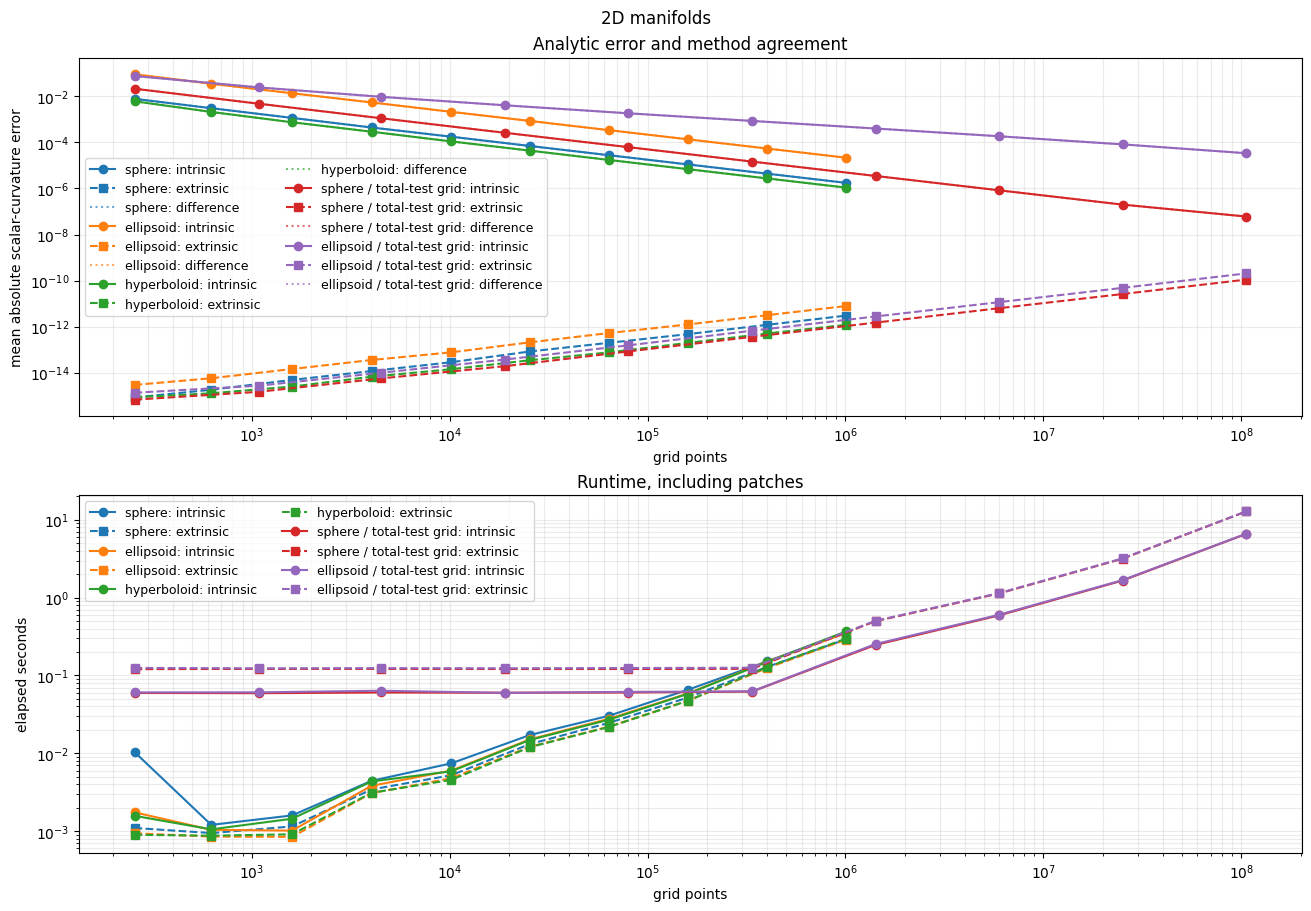

In [35]:
plot_results(results_2d, '2D manifolds');

## 3D and 4D manifolds (slow)

Run this section when ready for the slow grids. Select a subset with `SLOW_CASE_NAMES` in the setup.

In [ ]:
results_slow = run_cases(SLOW_CASES)

In [ ]:
plot_results(results_slow, '3D and 4D manifolds (slow)');

## Quartic, Gaussian and rippled graphs

Generic 2D graphs for ordinary finite-difference convergence.

In [38]:
results_graphs = run_cases(GRAPH_CASES)

Running quartic, (16, 16): embedding alone 6.14e-06 GB
quartic                     (16, 16)         intrinsic 0.0504  extrinsic 0.0538  difference 0.0034
Running quartic, (24, 24): embedding alone 1.38e-05 GB
quartic                     (24, 24)         intrinsic 0.0226  extrinsic 0.0253  difference 0.00387
Running quartic, (35, 35): embedding alone 2.94e-05 GB
quartic                     (35, 35)         intrinsic 0.0107  extrinsic 0.0116  difference 0.00282
Running quartic, (51, 51): embedding alone 6.24e-05 GB
quartic                     (51, 51)         intrinsic 0.00515  extrinsic 0.00526  difference 0.00169
Running quartic, (75, 75): embedding alone 0.000135 GB
quartic                     (75, 75)         intrinsic 0.00243  extrinsic 0.00236  difference 0.000904
Running quartic, (110, 110): embedding alone 0.00029 GB
quartic                     (110, 110)       intrinsic 0.00114  extrinsic 0.00108  difference 0.000458
Running quartic, (161, 161): embedding alone 0.000622 GB
quart

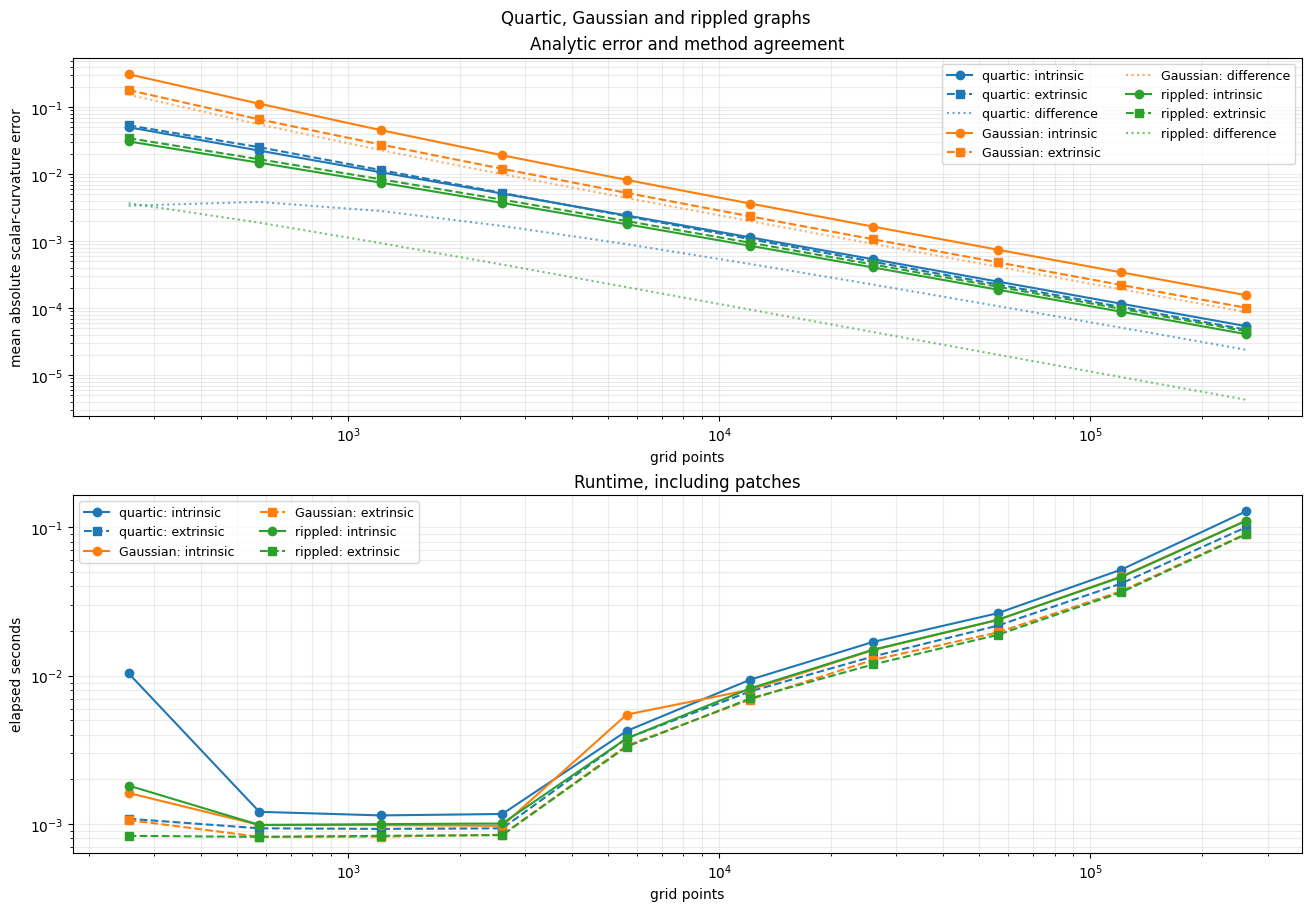

In [39]:
plot_results(results_graphs, 'Quartic, Gaussian and rippled graphs');

Check analytic errors before interpreting agreement between methods. These parameterizations are special for the extrinsic stencil: central differences of sin/cos multiply exact derivatives by `sin(h)/h`, and those of sinh/cosh by `sinh(h)/h`. Applying the same central difference twice gives the corresponding product of factors for second derivatives. Those factors cancel between the metric inverse and the second fundamental form in the Gauss contraction. In exact arithmetic, these ellipsoid, sphere and hyperboloid examples therefore have no truncation error with this stencil.

Their extrinsic errors largely measure floating-point roundoff, amplified approximately as `epsilon / h**2` by second differences (with geometry-dependent conditioning). Increasing density can increase this tiny error immediately. The intrinsic metric/Christoffel calculation does not share the cancellation, so its second-order truncation error initially decreases. It too eventually reaches a roundoff regime. Float64 is recommended; converting already rounded float32 samples back to float64 cannot recover lost information. Generic embeddings do not share this cancellation and should be tested separately for convergence.

Changing density also changes the retained nonperiodic domain because both methods crop three samples at each end. Near coordinate singularities, inspect maximum errors and conditioning as well as the mean. These plots alone cannot establish convergence on general manifolds.


For an ordinary convergence comparison, use the three graph cases in the final experiment section. The quartic graph is `z = 0.2*u**4 + 0.3*v**4 + 0.1*u*v`; the Gaussian bump is `z = 0.7*exp(-2*(u**2 + v**2))`; the rippled graph is `z = 0.2*sin(2*u) + 0.15*cos(3*v) + 0.1*u*v`. Their reference is `R = 2*(f_uu*f_vv - f_uv**2)/(1 + f_u**2 + f_v**2)**2`, using explicit analytic derivatives. The linear embedding coordinates `u,v` and nonlinear height do not share the quadric stencil factors. All three show decreasing errors in small CPU float64 checks at 16, 32, 64 and 128 samples per axis. No floating-point example avoids roundoff indefinitely; the 512 maximum is chosen to stay in the truncation-dominated range. On these nonperiodic grids, MAE also reflects the changing cropped domain; inspect convergence rates accordingly.
